# Belirti → Hastalık (Symptom2Disease) – Veri Analizi
Veri seti: Symptom2Disease (Kaggle). Hastaların belirtilerini kendi cümleleriyle anlattığı 1200 metin, 24 hastalık.
**Veri akışı:** raw → bronze (`symptom_bronze.csv`, 01 notebook'unda oluşturuldu) → **silver** (temizlenmiş metinler)

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sys.path.append("../src")          # src klasöründeki kendi dosyalarımızı kullanabilmek için
from metin_isleme import temizle

sns.set_theme(style="whitegrid")
FIG = "../results/figures/"
TAB = "../results/tables/"

In [2]:
bronze = pd.read_csv("../data/bronze/symptom_bronze.csv")
print("Boyut:", bronze.shape)
print("Sütunlar:", bronze.columns.tolist())
bronze.head()

Boyut: (1200, 3)
Sütunlar: ['Unnamed: 0', 'label', 'text']


,Unnamed: 0,label,text
0,0,Psoriasis,I have been experiencing a skin rash on my arm...
1,1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,2,Psoriasis,I have been experiencing joint pain in my fing...
3,3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,4,Psoriasis,"My nails have small dents or pits in them, and..."


Hastalık sayısı: 24
Hastalık başına metin: min = 50  maks = 50


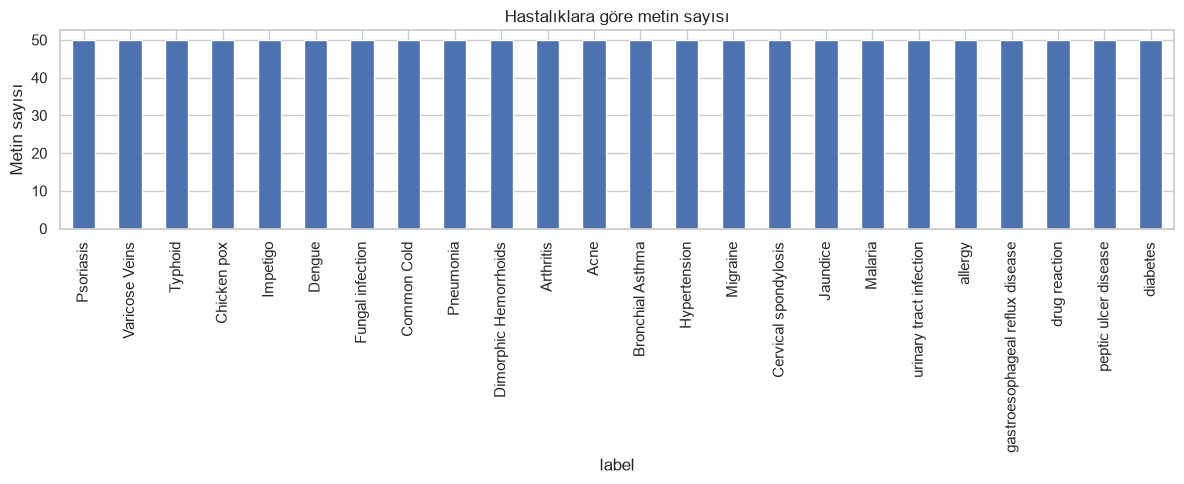

In [3]:
sinif = bronze["label"].value_counts()
print("Hastalık sayısı:", sinif.size)
print("Hastalık başına metin: min =", sinif.min(), " maks =", sinif.max())

plt.figure(figsize=(12, 5))
sinif.plot(kind="bar", color="#4C72B0")
plt.title("Hastalıklara göre metin sayısı"); plt.ylabel("Metin sayısı")
plt.tight_layout(); plt.savefig(FIG + "belirti_01_sinif_dagilimi.png", dpi=150); plt.show()

,Kelime sayısı
Ortalama,30.72
Medyan,30.00
Mod,30.00
Std. sapma,6.71
Min,12.00
Maks,55.00


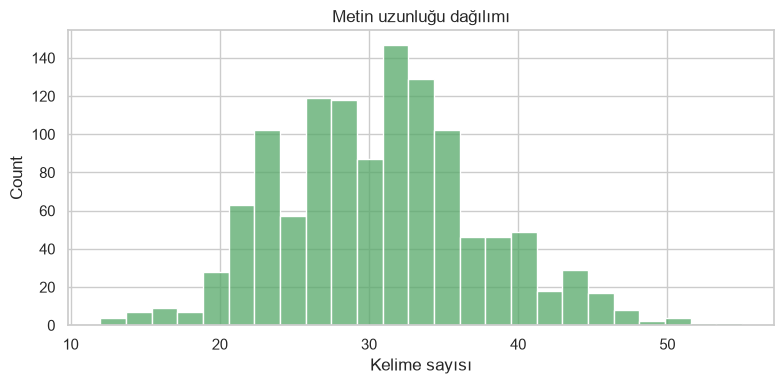

In [4]:
bronze["kelime_sayisi"] = bronze["text"].str.split().str.len()
k = bronze["kelime_sayisi"]
istat = pd.DataFrame({"Kelime sayısı": {
    "Ortalama": k.mean(), "Medyan": k.median(), "Mod": k.mode()[0],
    "Std. sapma": k.std(), "Min": k.min(), "Maks": k.max()}}).round(2)
istat.to_csv(TAB + "belirti_tanimlayici_istatistikler.csv")
display(istat)

plt.figure(figsize=(8, 4))
sns.histplot(k, bins=25, color="#55A868")
plt.title("Metin uzunluğu dağılımı"); plt.xlabel("Kelime sayısı")
plt.tight_layout(); plt.savefig(FIG + "belirti_02_metin_uzunlugu.png", dpi=150); plt.show()

In [5]:
print("Eksik değer:\n", bronze.isna().sum(), "\n")
print("Birebir tekrar eden metin sayısı:", bronze["text"].duplicated().sum())
print("\nEtiketler:", sorted(bronze["label"].unique()))

Eksik değer:
 Unnamed: 0       0
label            0
text             0
kelime_sayisi    0
dtype: int64 

Birebir tekrar eden metin sayısı: 47

Etiketler: ['Acne', 'Arthritis', 'Bronchial Asthma', 'Cervical spondylosis', 'Chicken pox', 'Common Cold', 'Dengue', 'Dimorphic Hemorrhoids', 'Fungal infection', 'Hypertension', 'Impetigo', 'Jaundice', 'Malaria', 'Migraine', 'Pneumonia', 'Psoriasis', 'Typhoid', 'Varicose Veins', 'allergy', 'diabetes', 'drug reaction', 'gastroesophageal reflux disease', 'peptic ulcer disease', 'urinary tract infection']


## Veri Temizleme (Bronze → Silver)
1. Satır numarası olan isimsiz sütun silinir.
2. Etiketler tek biçime getirilir (her kelime büyük harfle başlar).
3. Tekrar eden metinler silinir; aynı cümle hem eğitim hem testte olursa başarı yapay olarak yükselir (veri sızıntısı).
4. Metinler model için temizlenir: küçük harf, noktalama ve sayıların silinmesi, stopword'lerin atılması (olumsuzluk kelimeleri hariç), kök bulma (lemmatization).

In [6]:
silver = bronze.drop(columns=["Unnamed: 0", "kelime_sayisi"])
gunluk = [("İsimsiz sütun (satır no)", 1, "Silindi")]

eski = silver["label"].nunique()
silver["label"] = silver["label"].str.strip().str.title()
gunluk.append(("Tutarsız etiket yazımı", eski, "Tüm etiketler 'Baş Harfleri Büyük' biçimine getirildi"))

n = silver["text"].duplicated().sum()
silver = silver.drop_duplicates(subset="text").reset_index(drop=True)
gunluk.append(("Tekrar eden metin", n, "Silindi (veri sızıntısını önlemek için)"))

gunluk_df = pd.DataFrame(gunluk, columns=["Sorun", "Sayı", "Yapılan işlem"])
gunluk_df.to_csv(TAB + "belirti_on_isleme_gunlugu.csv", index=False)
print("Bronze:", bronze.shape, "→ Silver:", silver.shape)
gunluk_df

Bronze: (1200, 4) → Silver: (1153, 2)


,Sorun,Sayı,Yapılan işlem
0,İsimsiz sütun (satır no),1,Silindi
1,Tutarsız etiket yazımı,24,Tüm etiketler 'Baş Harfleri Büyük' biçimine ge...
2,Tekrar eden metin,47,Silindi (veri sızıntısını önlemek için)


In [7]:
silver["temiz_metin"] = silver["text"].map(temizle)

ornek = silver.iloc[0]
print("ÖNCE :", ornek["text"])
print("SONRA:", ornek["temiz_metin"])

ÖNCE : I have been experiencing a skin rash on my arms, legs, and torso for the past few weeks. It is red, itchy, and covered in dry, scaly patches.
SONRA: experiencing skin rash arm leg torso past week red itchy covered dry scaly patch


Temizlik sonrası farklı kelime sayısı: 1348


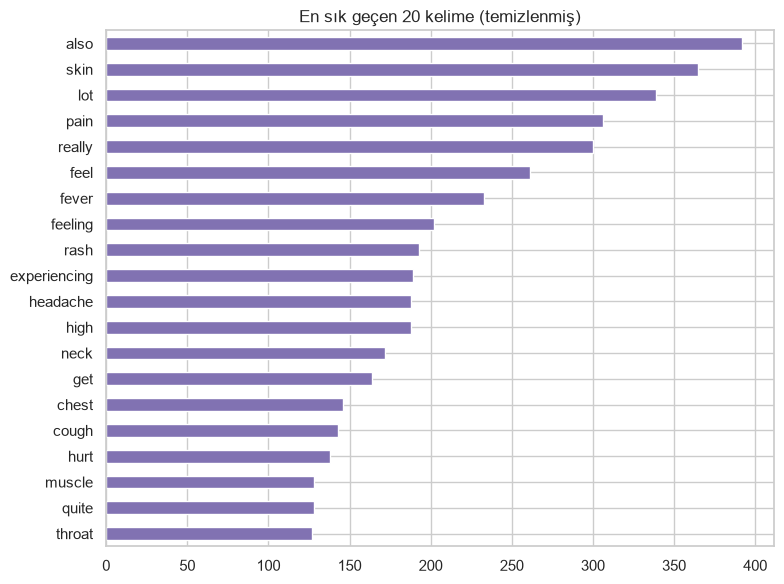

In [8]:
tum = Counter(w for m in silver["temiz_metin"] for w in m.split())
print("Temizlik sonrası farklı kelime sayısı:", len(tum))

plt.figure(figsize=(8, 6))
pd.Series(dict(tum.most_common(20))).sort_values().plot(kind="barh", color="#8172B2")
plt.title("En sık geçen 20 kelime (temizlenmiş)")
plt.tight_layout(); plt.savefig(FIG + "belirti_03_sik_kelimeler.png", dpi=150); plt.show()

In [9]:
silver.to_csv("../data/silver/symptom_silver.csv", index=False)
print("Kaydedildi: data/silver/symptom_silver.csv", silver.shape)
silver.sample(5, random_state=42)

Kaydedildi: data/silver/symptom_silver.csv (1153, 3)


,label,text,temiz_metin
767,Cervical Spondylosis,"I've had back pain, a cough that won't go away...",back pain cough wo go away limb weakness exper...
461,Dimorphic Hemorrhoids,"Recently, I've been having problems using the ...",recently problem using restroom going incredib...
787,Jaundice,I've been exhausted and experiencing nausea an...,exhausted experiencing nausea itching addition...
593,Bronchial Asthma,"I've had a nagging cough that won't go away, a...",nagging cough wo go away breathing become labo...
388,Common Cold,I've been quite exhausted and ill. My throat h...,quite exhausted throat quite painful fairly na...
